# Dataset Validation: Beta(α, β) Conversion Rate Distribution

**Eval plan Step 1.3** — Validate that the synthetic dataset has the intended heavy-tailed shape and select Beta parameters for the main experiments.

Goals:
1. Confirm the distribution is J-shaped (most users near zero, heavy right tail)
2. Understand how α and β control the shape and mean rate
3. Pick 2–3 parameter settings for the pilot sweep (Step 3)

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.stats import beta as beta_dist

from simulation.datasets import (
    PopulationConfig,
    generate_synthetic_population,
    describe_population,
    plot_conversion_rate_histogram,
)

RNG = np.random.default_rng(42)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

## 1. Named presets: Sparse vs Moderate attribution

| Config | α | β | E[rate] | Interpretation |
|--------|---|---|---------|----------------|
| SPARSE | 0.3 | 3.0 | 0.091 | Most users rarely convert — clear TCT advantage regime |
| MODERATE | 0.5 | 2.0 | 0.200 | More active population — smaller but visible advantage |

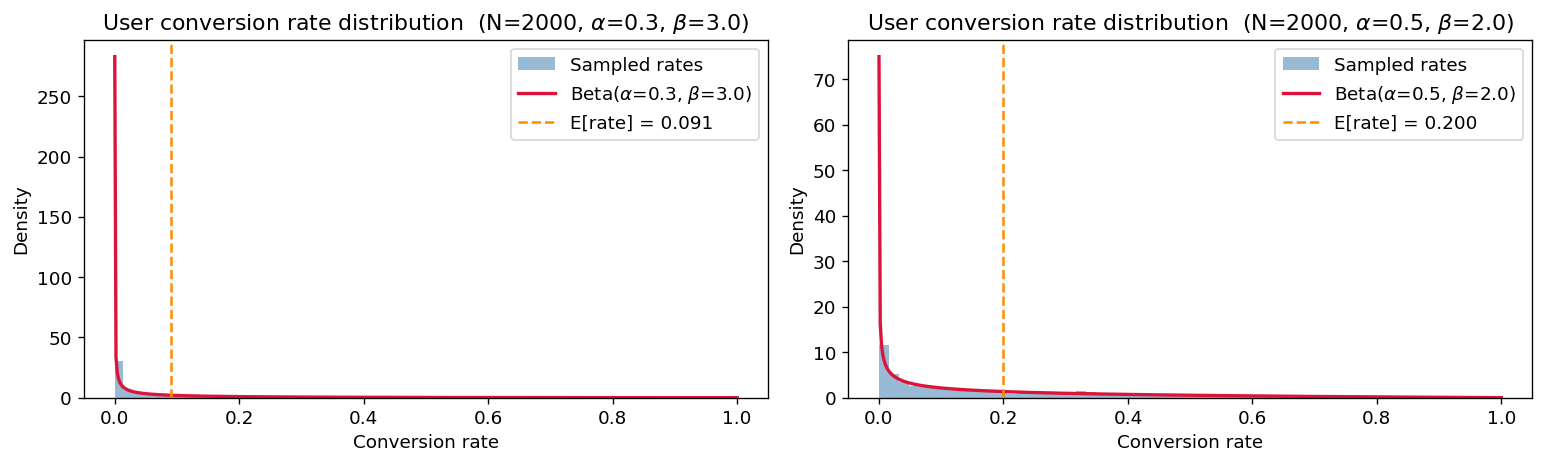

In [3]:
SPARSE   = PopulationConfig(n_users=2000, alpha=0.3, beta=3.0, epsilon_budget=1.0, delta_budget=1e-5)
MODERATE = PopulationConfig(n_users=2000, alpha=0.5, beta=2.0, epsilon_budget=1.0, delta_budget=1e-5)

pop_sparse   = generate_synthetic_population(SPARSE,   np.random.default_rng(42))
pop_moderate = generate_synthetic_population(MODERATE, np.random.default_rng(42))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
plot_conversion_rate_histogram(pop_sparse,   SPARSE,   ax=axes[0])
plot_conversion_rate_histogram(pop_moderate, MODERATE, ax=axes[1])
plt.tight_layout()
plt.show()

## 2. Summary statistics

In [4]:
import pandas as pd

stats_sparse   = describe_population(pop_sparse)
stats_moderate = describe_population(pop_moderate)

df = pd.DataFrame([stats_sparse, stats_moderate],
                  index=['SPARSE (α=0.3, β=3.0)', 'MODERATE (α=0.5, β=2.0)'])
df.style.format('{:.4f}').set_caption('Conversion rate summary statistics')

,n_users,mean,std,median,p10,p25,p75,p90,p99,frac_below_0.05,frac_below_0.20,frac_above_0.50
"SPARSE (α=0.3, β=3.0)",2000.0000,0.0879,0.1358,0.0259,0.0001,0.0020,0.1154,0.2706,0.6189,0.6015,0.8480,0.0240
"MODERATE (α=0.5, β=2.0)",2000.0000,0.2021,0.2125,0.1250,0.0048,0.0282,0.3226,0.5273,0.8412,0.3270,0.6220,0.1160


## 3. Parameter exploration grid

Vary α and β to see how they control the shape.
- **α < 1**: J-shaped (heavy mass near 0) — what we want
- **α ≥ 1**: bell-shaped or uniform — not suitable
- **larger β**: pushes mean lower, more inactive users

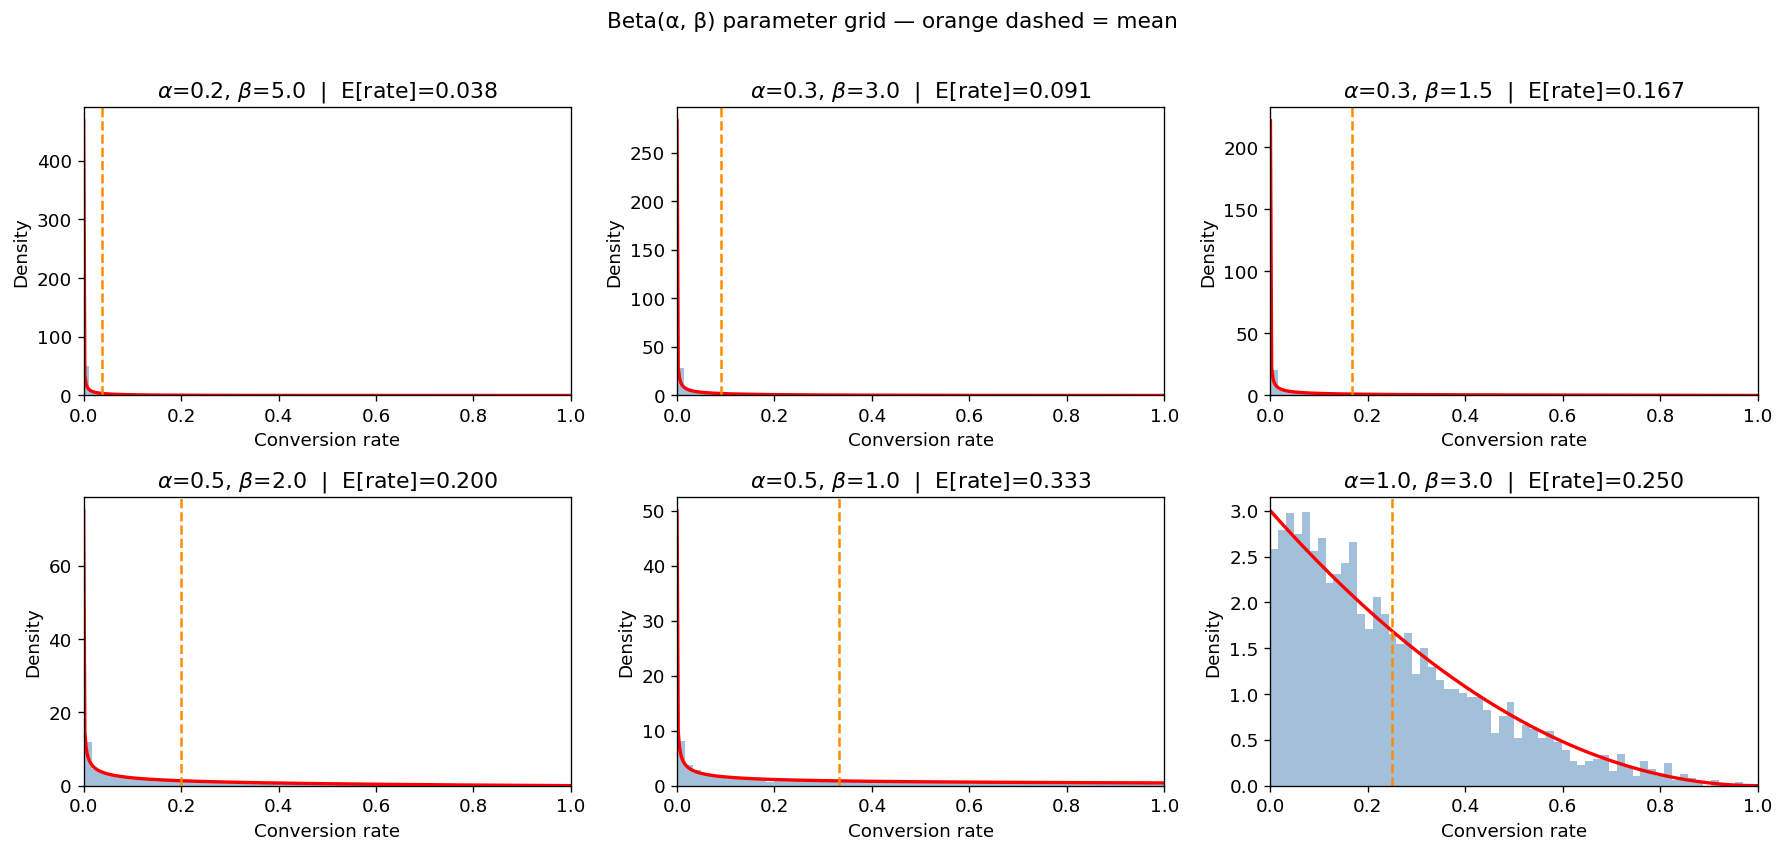

In [5]:
configs = [
    (0.2, 5.0),   # very sparse — mean ≈ 0.038
    (0.3, 3.0),   # sparse (SPARSE preset) — mean ≈ 0.091
    (0.3, 1.5),   # sparse, wider spread — mean ≈ 0.167
    (0.5, 2.0),   # moderate (MODERATE preset) — mean ≈ 0.200
    (0.5, 1.0),   # uniform-like right skew — mean ≈ 0.333
    (1.0, 3.0),   # bell-shaped (alpha=1 boundary) — mean ≈ 0.250
]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
x = np.linspace(1e-4, 1 - 1e-4, 400)

for ax, (a, b) in zip(axes.flat, configs):
    cfg = PopulationConfig(n_users=3000, alpha=a, beta=b,
                           epsilon_budget=1.0, delta_budget=1e-5)
    pop = generate_synthetic_population(cfg, np.random.default_rng(0))
    rates = np.array([u.conversion_rate for u in pop.all_users])

    ax.hist(rates, bins=60, density=True, alpha=0.5, color='steelblue')
    ax.plot(x, beta_dist.pdf(x, a, b), 'r-', lw=2)
    ax.axvline(cfg.expected_rate, color='darkorange', linestyle='--', lw=1.5)

    ax.set_title(rf'$\alpha$={a}, $\beta$={b}  |  E[rate]={cfg.expected_rate:.3f}')
    ax.set_xlabel('Conversion rate')
    ax.set_ylabel('Density')
    ax.set_xlim(0, 1)

fig.suptitle('Beta(α, β) parameter grid — orange dashed = mean', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 4. Effect of α and β on key simulation quantities

The expected hit probability `q` (probability a round produces a top) depends on:
- The mean conversion rate E[rate] = α/(α+β)
- The number of active users N
- The threshold T

Rough approximation: expected A_r ≈ N × E[rate], so the probability of crossing threshold T
scales with how far N×E[rate] is below T (more margin → smaller q → bigger TCT advantage).

In [ ]:
from scipy.stats import norm

N = 500
query_epsilon = 0.01   # Laplace noise scale = 1/epsilon
noise_scale = 1.0 / query_epsilon  # Laplace(0, 1/eps)

alpha_vals = [0.2, 0.3, 0.4, 0.5]
beta_vals  = [1.5, 2.0, 3.0, 5.0]

rows = []
for a in alpha_vals:
    for b in beta_vals:
        mean_rate = a / (a + b)
        mean_A    = N * mean_rate
        # approximate q using Gaussian approximation for A_r + Laplace noise
        # A_r ~ approx Normal(mean_A, sqrt(N * mean_rate * (1-mean_rate)))
        # Laplace noise has std = sqrt(2) * noise_scale
        # Combined std ≈ sqrt(var_A + 2*noise_scale^2)
        std_combined = np.sqrt(N * mean_rate * (1 - mean_rate) + 2 * noise_scale**2)
        T_low  = mean_A + 1 * std_combined   # low threshold:  q ≈ 0.16
        T_mid  = mean_A + 2 * std_combined   # mid threshold:  q ≈ 0.023
        T_high = mean_A + 3 * std_combined   # high threshold: q ≈ 0.0013
        rows.append({
            'α': a, 'β': b,
            'E[rate]': f'{mean_rate:.3f}',
            'E[A_r]': f'{mean_A:.1f}',
            'T (q≈0.16)': f'{T_low:.1f}',
            'T (q≈0.023)': f'{T_mid:.1f}',
            'T (q≈0.001)': f'{T_high:.1f}',
        })

df2 = pd.DataFrame(rows).set_index(['α', 'β'])
df2.style.set_caption(f'Approximate threshold values for N={N}, ε={query_epsilon}')

## 5. Selected parameters

Edit the cell below to record the parameter settings you're taking forward to the pilot sweep.
Aim for 2–3 settings that cover a range of q values (low, medium) where TCT's advantage is visible.

In [7]:
# ── Candidate settings for Step 3 pilot sweep ──────────────────────────────
#
# Setting A (sparse, clear TCT advantage):
SETTING_A = dict(alpha=0.3, beta=3.0, threshold=None)  # fill threshold after seeing table above
#
# Setting B (moderate activity):
SETTING_B = dict(alpha=0.5, beta=2.0, threshold=None)
#
# Setting C (very sparse, stress test):
SETTING_C = dict(alpha=0.2, beta=5.0, threshold=None)
#
# ───────────────────────────────────────────────────────────────────────────

print('Candidate settings recorded. Fill in thresholds from the table in Section 4.')

Candidate settings recorded. Fill in thresholds from the table in Section 4.
